In [1]:
# Import libraries
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Use dark background theme
plt.style.use('dark_background')

print("Libraries loaded successfully!")

Libraries loaded successfully!


In [2]:
# Load the dataset
data = load_breast_cancer()

# Print dataset information
print("="*80)
print("BREAST CANCER WISCONSIN DATASET")
print("="*80)
print(f"Number of samples: {data.data.shape[0]}")
print(f"Number of features: {data.data.shape[1]}")
print(f"\nClasses: {data.target_names}")
print(f"  - 0 = Malignant (cancerous)")
print(f"  - 1 = Benign (non-cancerous)")
print(f"\nClass distribution:")
unique, counts = np.unique(data.target, return_counts=True)
for label, count in zip(unique, counts):
    print(f"  {data.target_names[label]}: {count} samples ({count/len(data.target)*100:.1f}%)")
print("="*80)

BREAST CANCER WISCONSIN DATASET
Number of samples: 569
Number of features: 30

Classes: ['malignant' 'benign']
  - 0 = Malignant (cancerous)
  - 1 = Benign (non-cancerous)

Class distribution:
  malignant: 212 samples (37.3%)
  benign: 357 samples (62.7%)


In [3]:
# Print all feature names
print("\nAll 30 Features:")
print("="*80)
for i, feature_name in enumerate(data.feature_names, 1):
    print(f"{i:2d}. {feature_name}")
print("="*80)


All 30 Features:
 1. mean radius
 2. mean texture
 3. mean perimeter
 4. mean area
 5. mean smoothness
 6. mean compactness
 7. mean concavity
 8. mean concave points
 9. mean symmetry
10. mean fractal dimension
11. radius error
12. texture error
13. perimeter error
14. area error
15. smoothness error
16. compactness error
17. concavity error
18. concave points error
19. symmetry error
20. fractal dimension error
21. worst radius
22. worst texture
23. worst perimeter
24. worst area
25. worst smoothness
26. worst compactness
27. worst concavity
28. worst concave points
29. worst symmetry
30. worst fractal dimension


##Exercise 1: Logistic Regression from Scratch

In [5]:
ex1_feature_indices = [20, 21]
X_ex1 = data.data[:, ex1_feature_indices]
y_ex1 = data.target

X_train_ex1, X_test_ex1, y_train_ex1, y_test_ex1 = train_test_split(
    X_ex1, y_ex1, test_size=0.2, random_state=42, stratify=y_ex1
)
scaler_ex1 = StandardScaler()
X_train_ex1_scaled = scaler_ex1.fit_transform(X_train_ex1)
X_test_ex1_scaled = scaler_ex1.transform(X_test_ex1)

X_train_ex1_bias = np.column_stack([np.ones(len(X_train_ex1_scaled)), X_train_ex1_scaled])
X_test_ex1_bias = np.column_stack([np.ones(len(X_test_ex1_scaled)), X_test_ex1_scaled])

# 3. Initialize weights a
np.random.seed(42)
w_ex1 = np.random.randn(3) * 0.01
eta_ex1 = 0.1
epochs_ex1 = 1000
cost_ex1 = []

for epoch in range(epochs_ex1):
    z = X_train_ex1_bias @ w_ex1
    h = 1 / (1 + np.exp(-z))

    error = h - y_train_ex1
    w_ex1 = w_ex1 - eta_ex1 * (X_train_ex1_bias.T @ error) / len(X_train_ex1_scaled)

    loss = -np.mean(y_train_ex1 * np.log(h + 1e-10) + (1 - y_train_ex1) * np.log(1 - h + 1e-10))
    cost_ex1.append(loss)

train_preds_ex1 = (1 / (1 + np.exp(-(X_train_ex1_bias @ w_ex1))) >= 0.5).astype(int)
test_preds_ex1 = (1 / (1 + np.exp(-(X_test_ex1_bias @ w_ex1))) >= 0.5).astype(int)

train_acc_ex1 = np.mean(train_preds_ex1 == y_train_ex1) * 100
test_acc_ex1 = np.mean(test_preds_ex1 == y_test_ex1) * 100# 1. Select 2 features: 'worst radius' (20) and 'worst texture' (21)
ex1_feature_indices = [20, 21]
X_ex1 = data.data[:, ex1_feature_indices]
y_ex1 = data.target

X_train_ex1, X_test_ex1, y_train_ex1, y_test_ex1 = train_test_split(
    X_ex1, y_ex1, test_size=0.2, random_state=42, stratify=y_ex1
)
scaler_ex1 = StandardScaler()
X_train_ex1_scaled = scaler_ex1.fit_transform(X_train_ex1)
X_test_ex1_scaled = scaler_ex1.transform(X_test_ex1)

X_train_ex1_bias = np.column_stack([np.ones(len(X_train_ex1_scaled)), X_train_ex1_scaled])
X_test_ex1_bias = np.column_stack([np.ones(len(X_test_ex1_scaled)), X_test_ex1_scaled])

np.random.seed(42)
w_ex1 = np.random.randn(3) * 0.01
eta_ex1 = 0.1
epochs_ex1 = 1000
cost_ex1 = []

for epoch in range(epochs_ex1):
    z = X_train_ex1_bias @ w_ex1
    h = 1 / (1 + np.exp(-z))

    error = h - y_train_ex1
    w_ex1 = w_ex1 - eta_ex1 * (X_train_ex1_bias.T @ error) / len(X_train_ex1_scaled)

    loss = -np.mean(y_train_ex1 * np.log(h + 1e-10) + (1 - y_train_ex1) * np.log(1 - h + 1e-10))
    cost_ex1.append(loss)

# 4.  Training and Testing
train_preds_ex1 = (1 / (1 + np.exp(-(X_train_ex1_bias @ w_ex1))) >= 0.5).astype(int)
test_preds_ex1 = (1 / (1 + np.exp(-(X_test_ex1_bias @ w_ex1))) >= 0.5).astype(int)

train_acc_ex1 = np.mean(train_preds_ex1 == y_train_ex1) * 100
test_acc_ex1 = np.mean(test_preds_ex1 == y_test_ex1) * 100
print("="*70)
print("EXERCISE 1: LOGISTIC REGRESSION FROM SCRATCH")
print("="*70)
print(f"Features: {data.feature_names[ex1_feature_indices[0]]}")
print(f"          {data.feature_names[ex1_feature_indices[1]]}")
print(f"\nTraining Accuracy: {train_acc_ex1:.2f}%")
print(f"Testing Accuracy:  {test_acc_ex1:.2f}%")
print(f"Final Cost: {cost_ex1[-1]:.6f}")
print("="*70)

EXERCISE 1: LOGISTIC REGRESSION FROM SCRATCH
Features: worst radius
          worst texture

Training Accuracy: 94.51%
Testing Accuracy:  92.98%
Final Cost: 0.164769


##Exercise 2: Deep Neural Network with ALL Features (PyTorch)

In [19]:
import torch
import torch.nn as nn
import torch.optim as optim
#  Prepare data using ALL 30 features
X_all = data.data
y_all = data.target

X_train_all, X_test_all, y_train_all, y_test_all = train_test_split(
    X_all, y_all, test_size=0.2, random_state=42, stratify=y_all
)

scaler_all = StandardScaler()
X_train_all_scaled = scaler_all.fit_transform(X_train_all)
X_test_all_scaled = scaler_all.transform(X_test_all)

# Convert to PyTorch tensors
X_train_t = torch.FloatTensor(X_train_all_scaled)
y_train_t = torch.FloatTensor(y_train_all).unsqueeze(1)
X_test_t = torch.FloatTensor(X_test_all_scaled)
y_test_t = torch.FloatTensor(y_test_all).unsqueeze(1)

class DeepNN30(nn.Module):
    def __init__(self):
        super(DeepNN30, self).__init__()
        self.fc1 = nn.Linear(30, 8)
        self.fc2 = nn.Linear(8, 6)
        self.fc3 = nn.Linear(6, 4)
        self.fc4 = nn.Linear(4, 1)
        self.relu = nn.ReLU()
        self.sigmoid = nn.Sigmoid()   #

    def forward(self, x):
        x = self.relu(self.fc1(x))
        x = self.relu(self.fc2(x))
        x = self.relu(self.fc3(x))
        x = self.sigmoid(self.fc4(x))
        return x

torch.manual_seed(42)
model_ex2 = DeepNN30()
criterion_ex2 = nn.BCELoss()
optimizer_ex2 = optim.Adam(model_ex2.parameters(), lr=0.01)

#  Train the network for 1000 epochs
cost_ex2 = []
for epoch in range(1000):
    outputs = model_ex2(X_train_t)
    loss = criterion_ex2(outputs, y_train_t)

    optimizer_ex2.zero_grad()
    loss.backward()
    optimizer_ex2.step()

    cost_ex2.append(loss.item())

#   Training and Testing
with torch.no_grad():
    train_preds_ex2 = (model_ex2(X_train_t).numpy() >= 0.5).astype(int).flatten()
    test_preds_ex2 = (model_ex2(X_test_t).numpy() >= 0.5).astype(int).flatten()

    train_acc_ex2 = np.mean(train_preds_ex2 == y_train_all) * 100
    test_acc_ex2 = np.mean(test_preds_ex2 == y_test_all) * 100
# Count parameters
total_params_ex2 = sum(p.numel() for p in model_ex2.parameters())

print("="*70)
print("EXERCISE 2: DEEP NEURAL NETWORK (ALL 30 FEATURES)")
print("="*70)
print(f"Architecture: 30 → 8 → 6 → 4 → 1")
print(f"Total parameters: {total_params_ex2}")
print(f"\nTraining Accuracy: {train_acc_ex2:.2f}%")
print(f"Testing Accuracy:  {test_acc_ex2:.2f}%")
print(f"Final Loss: {cost_ex2[-1]:.6f}")
print("="*70)

EXERCISE 2: DEEP NEURAL NETWORK (ALL 30 FEATURES)
Architecture: 30 → 8 → 6 → 4 → 1
Total parameters: 335

Training Accuracy: 99.78%
Testing Accuracy:  95.61%
Final Loss: 0.019447


##Exercise 3: Visualize and Compare Results   

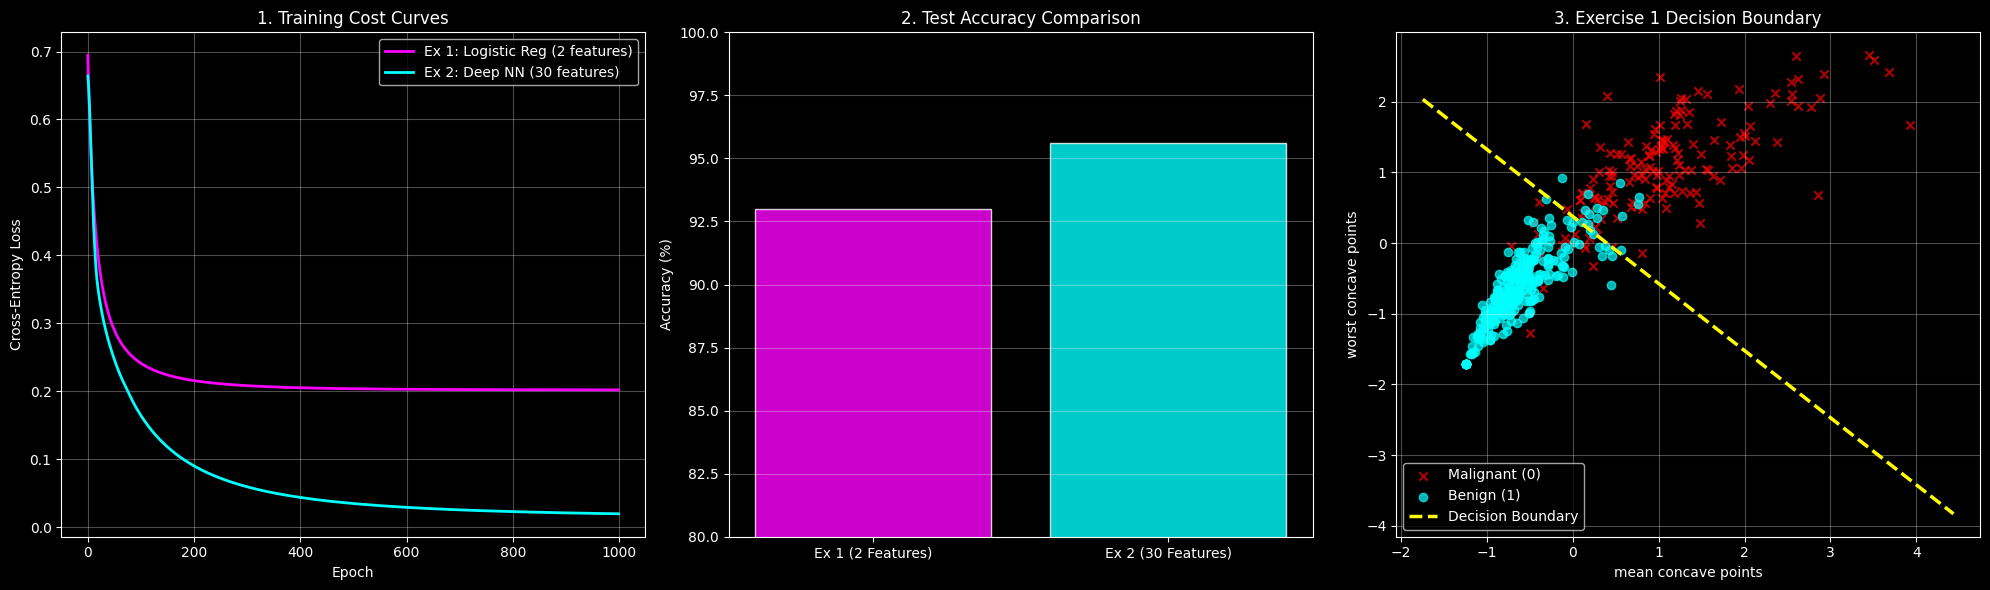


COMPARISON: EXERCISE 1 vs EXERCISE 2
Exercise 1 (2 features):   Test Accuracy = 92.98%
Exercise 2 (30 features):  Test Accuracy = 95.61%

Improvement: 2.63% better with all features!


In [20]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
axes[0].plot(cost_ex1, label='Ex 1: Logistic Reg (2 features)', color='magenta', linewidth=2)
axes[0].plot(cost_ex2, label='Ex 2: Deep NN (30 features)', color='cyan', linewidth=2)
axes[0].set_title('1. Training Cost Curves')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Cross-Entropy Loss')
axes[0].legend()
axes[0].grid(True, alpha=0.3)
models_labels = ['Ex 1 (2 Features)', 'Ex 2 (30 Features)']
test_accuracies = [test_acc_ex1, test_acc_ex2]
axes[1].bar(models_labels, test_accuracies, color=['magenta', 'cyan'], alpha=0.8, edgecolor='white')
axes[1].set_ylim([80, 100])
axes[1].set_title('2. Test Accuracy Comparison')
axes[1].set_ylabel('Accuracy (%)')
axes[1].grid(True, alpha=0.3, axis='y')
axes[2].scatter(X_train_ex1_scaled[y_train_ex1 == 0, 0], X_train_ex1_scaled[y_train_ex1 == 0, 1],
                c='red', marker='x', label='Malignant (0)', alpha=0.7)
axes[2].scatter(X_train_ex1_scaled[y_train_ex1 == 1, 0], X_train_ex1_scaled[y_train_ex1 == 1, 1],
                c='cyan', marker='o', label='Benign (1)', alpha=0.7)
x1_line = np.linspace(X_train_ex1_scaled[:, 0].min() - 0.5, X_train_ex1_scaled[:, 0].max() + 0.5, 100)
x2_line = -(w_ex1[0] + w_ex1[1] * x1_line) / w_ex1[2]
axes[2].plot(x1_line, x2_line, 'yellow', linestyle='--', linewidth=2.5, label='Decision Boundary')
axes[2].set_title('3. Exercise 1 Decision Boundary')
axes[2].set_xlabel(data.feature_names[ex1_feature_indices[0]])
axes[2].set_ylabel(data.feature_names[ex1_feature_indices[1]])
axes[2].legend()
axes[2].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
print("\n" + "="*70)
print("COMPARISON: EXERCISE 1 vs EXERCISE 2")
print("="*70)
print(f"Exercise 1 (2 features):   Test Accuracy = {test_acc_ex1:.2f}%")
print(f"Exercise 2 (30 features):  Test Accuracy = {test_acc_ex2:.2f}%")
print(f"\nImprovement: {test_acc_ex2 - test_acc_ex1:.2f}% better with all features!")
print("="*70)